In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import tensorflow as tf
from tensorflow import keras

In [3]:
from tensorflow.keras.models import Sequential , Model
from tensorflow.keras.layers import Input , Flatten , Dense , Dropout , Conv2D , MaxPool2D , GlobalAveragePooling2D

In [4]:
# optimizers  
from tensorflow.keras.optimizers import SGD,Adam 

In [5]:
# loss Function  
from tensorflow.keras.losses import MeanSquaredError, MeanAbsoluteError , CategoricalCrossentropy,SparseCategoricalCrossentropy,BinaryCrossentropy

In [6]:
# metrics  
from tensorflow.keras.metrics import Accuracy, Precision , Recall


In [7]:
# callback  
from tensorflow.keras.callbacks import EarlyStopping

In [10]:
# Load MNIST data
data = np.load('mnist.npz')

data

NpzFile 'mnist.npz' with keys: x_test, x_train, y_train, y_test

In [11]:
# split the dataset
x_train=data["x_train"]
x_test=data["x_test"]
y_train=data["y_train"]
y_test=data["y_test"]

print(f"Shape of x_train : {x_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of x_test: {x_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of x_train : (60000, 28, 28)
Shape of y_train: (60000,)
Shape of x_test: (10000, 28, 28)
Shape of y_test: (10000,)


In [16]:
x_train.dtype
# already in Float32 format
# to change x_train = x_train.astype("float32") / 255.0

dtype('float32')

In [17]:
# Normalize pixel values to be between 0 and 1
x_train = x_train/ 255.0
x_test = x_test / 255.0

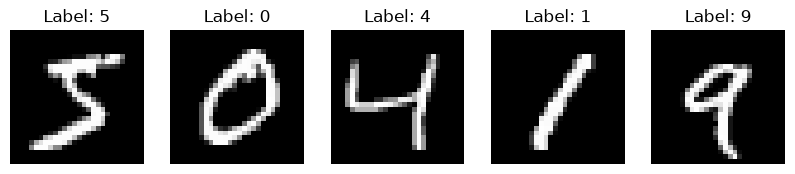

In [32]:
# Plot the first 5 images from the training set
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.show()

In [33]:
# Define the Network Architecture (Feedforward Neural Network)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input , Flatten , Dense , Dropout , Conv2D , MaxPool2D , GlobalAveragePooling2D

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    
    Dense(256,activation='relu'),
    #Dropout(0.2),
    
    Dense(128, activation='relu'),
    #Dropout(0.2),
    
    Dense(10, activation='softmax')
])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
# compile and train the model  
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss= SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

# train model  
history = model.fit(
    x_train,
    y_train, 
    epochs=10,
    batch_size=32,
    validation_data=(x_test,y_test)
    # validation_split=0.1 
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.1123 - loss: 2.3016 - val_accuracy: 0.1135 - val_loss: 2.3011
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.1124 - loss: 2.3013 - val_accuracy: 0.1135 - val_loss: 2.3011
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.1124 - loss: 2.3013 - val_accuracy: 0.1135 - val_loss: 2.3011
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.1124 - loss: 2.3013 - val_accuracy: 0.1135 - val_loss: 2.3011
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.1124 - loss: 2.3013 - val_accuracy: 0.1135 - val_loss: 2.3011
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.1124 - loss: 2.3013 - val_accuracy: 0.1135 - val_loss: 2.3011
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.1124 - loss: 2.3013 - val_accuracy: 0.1135 - val_loss: 2.3011
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.1124 - loss: 2.3013 - 

In [36]:
# Evaluate the network
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1135 - loss: 2.3011
Test Loss: 2.3010895252227783
Test Accuracy: 0.11349999904632568


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predicted Digit: 1
Actual Digit: 7


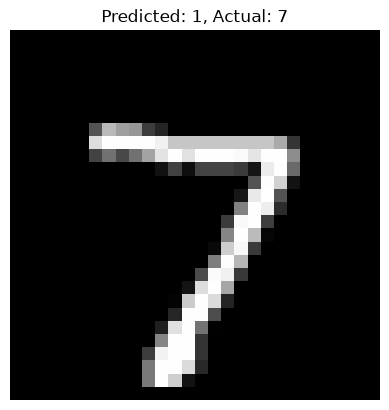

In [37]:
# Predict on the test data
predictions = model.predict(x_test)

# Get the predicted class for the first test image
predicted_label = np.argmax(predictions[0])

print(f"Predicted Digit: {predicted_label}")
print(f"Actual Digit: {y_test[0]}")

# Show the image
plt.imshow(x_test[0], cmap='gray')
plt.title(f"Predicted: {predicted_label}, Actual: {y_test[0]}")
plt.axis('off')
plt.show()

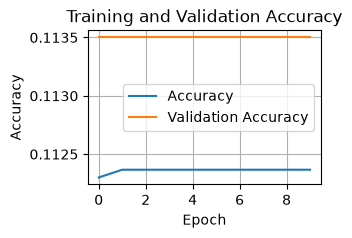

In [38]:
# Plot Accuracy
plt.figure(figsize=(3, 2))

plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()



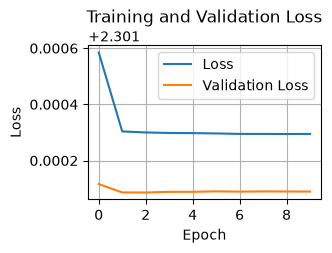

In [39]:
# Plot Loss
plt.figure(figsize=(3, 2))
plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()